In [1]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import scipy
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [2]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [3]:

def add_peak(ax, x, text, y_text, y_line_top=200):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 3, y_text),
        rotation=90,
        fontsize=11
    )

In [4]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )

In [5]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [7]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, edges, counts



In [8]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [9]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, E_edge,  counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, E_edge,  total_counts, total_time

# inizio

In [10]:
FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 4.179423e-01,
            "b": 1.2696e-01,
            "c": 1.514025e-08,
        },
    },
}

In [14]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.42

BINS = np.arange(ENERGY_RANGE[0], ENERGY_RANGE[1], BIN_WIDTH)

BACKGROUND_PEAKS = {

   "???" : {"E":860.45, "N":0},
   "84Rb":  {"E":881.6, "N":0},
    "88Y":  {"E":898, "N":0},
    "228Ac":  {"E":911.204, "N":0}
}

BACKGROUND_PEAKS = {

   "208Tl" : {"E":860.45, "N":0},
   "84Rb":  {"E":881.6, "N":0},
    "88Y":  {"E":898, "N":0},
    "228Ac":  {"E":911.204, "N":0}
}

BACKGROUND_PEAKS = {

    "²⁰⁸Tl": {"E": 860.45, "N": 0},
    "⁸⁴Rb":  {"E": 881.6,  "N": 0},
    "⁸⁸Y":   {"E": 898,    "N": 0},
    "²²⁸Ac": {"E": 911.204, "N": 0}
}



SIGNAL = {
    "mu": 871,
    "roi": (840, 920),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [15]:
E_tot, E_edge, Ntot, t_tot = build_total_spectrum(FILES, BINS)


print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)

Total counts = 42047 in 136.9 days


(35.0, 500.0)

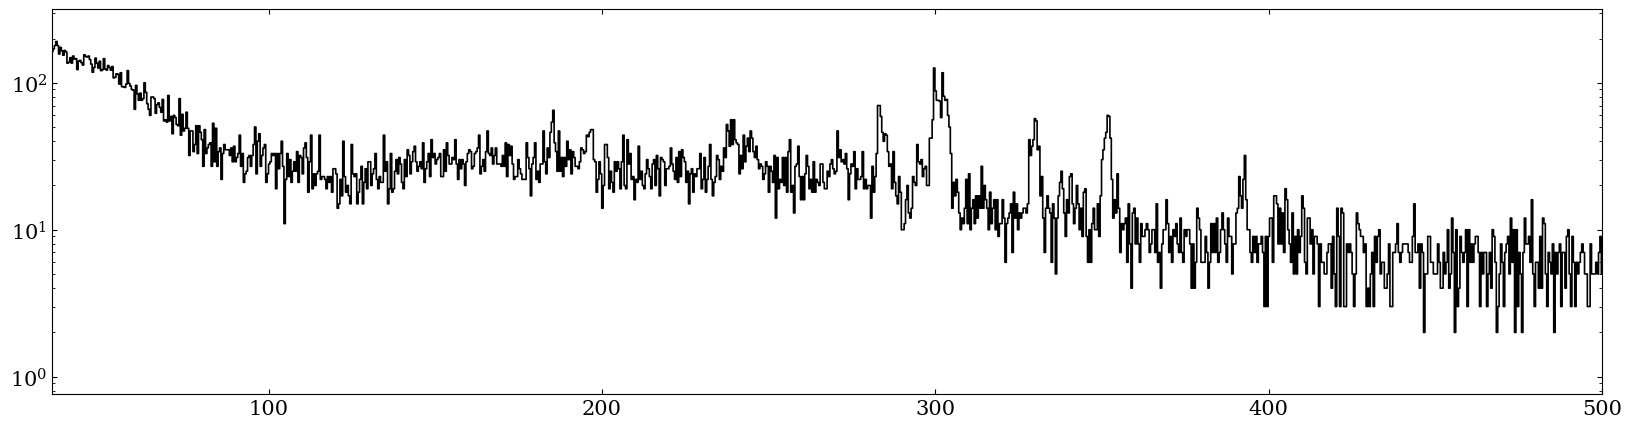

In [16]:
plt.figure(figsize=(20,5))
plt.step(E_tot, Ntot, where="mid", color="black")
plt.yscale('log')
plt.vlines(1460, 1, 100, color='red', linestyle='dashed')
plt.xlim(35,500)

In [17]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

In [18]:
bin_edges = BINS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ============================================================
# ROI
# ============================================================
roi_mask = (
    (bin_centers >= SIGNAL["roi"][0]) &
    (bin_centers <= SIGNAL["roi"][1])
)

# Conteggi nella ROI
counts_roi = Ntot[roi_mask]

# Centri dei bin nella ROI
E_roi = bin_centers[roi_mask]

# Edge dei bin nella ROI
idx = np.where(roi_mask)[0]
bin_edges_roi = bin_edges[idx[0]:idx[-1] + 2]

# Larghezza dei bin (costante)
bin_width = bin_edges_roi[1] - bin_edges_roi[0]


In [19]:


edges_low = bin_edges_roi[:-1]
edges_high = bin_edges_roi[1:]

# ============================================================
# CDF GAUSSIAN (PyTensor safe)
# ============================================================
def gaussian_cdf(x, mu, sigma):
    return 0.5 * (1.0 + pt.erf((x - mu) / (sigma * pt.sqrt(2.0))))

def bin_integral(mu, sigma, low, high):
    return gaussian_cdf(high, mu, sigma) - gaussian_cdf(low, mu, sigma)

# ============================================================
# MODEL
# ============================================================
with pm.Model() as model:
    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================
    A_bg = []
    mu_bg = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        #A = pm.HalfNormal(f"A_{name}", sigma=np.max(counts_roi)/2)
        A = pm.HalfFlat(f"A_{name}")
        mu = pm.Normal(f"mu_{name}", mu=fit["E"], sigma=0.5)

        A_bg.append(A)
        mu_bg.append(mu)

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)

    # ========================================================
    # SIGNAL
    # ========================================================
    #A_signal = pm.HalfNormal("A_signal", sigma=np.max(counts_roi))
    A_signal = pm.HalfFlat("A_signal")
    mu_signal = pm.Normal("mu_signal", mu=SIGNAL["mu"], sigma=0.25)

    sigma = sigma_fun(mu_signal)  # must be PyTensor-compatible

    # ========================================================
    # FLAT BACKGROUND
    # ========================================================
    bin_width = edges_high - edges_low



    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi)
    )



    Q_bins = Q * bin_width
    '''
    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi)
    )

    Q_bins = Q * np.ones_like(edges_low) '''   
    
    
    # ========================================================
    # EXACT BIN INTEGRALS
    # ========================================================
    sig = bin_integral(mu_signal, sigma, edges_low, edges_high)

    bg = pt.stack([
        bin_integral(mu_bg[i], sigma, edges_low, edges_high)
        for i in range(len(BACKGROUND_PEAKS))
    ])

    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================
    lambda_E = (
        Q_bins
        + A_signal * sig
        + pt.sum(A_bg[:, None] * bg, axis=0)
    )

    lambda_E = pt.clip(lambda_E, 1e-9, np.inf)

    # ========================================================
    # LIKELIHOOD
    # ========================================================
    pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi
    )

   

    # ========================================================
    # SAMPLING
    # ========================================================
    trace = pm.sample(
        draws=2000,
        tune=4000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.95,
        init="jitter+adapt_diag",
        return_inferencedata=True
    )




Initializing NUTS using jitter+adapt_diag...
/home/ritaferi/pymc-env/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²⁰⁸Tl, mu_²⁰⁸Tl, A_⁸⁴Rb, mu_⁸⁴Rb, A_⁸⁸Y, mu_⁸⁸Y, A_²²⁸Ac, mu_²²⁸Ac, A_signal, mu_signal, Q]


Output()

Sampling 4 chains for 4_000 tune and 2_000 draw iterations (16_000 + 8_000 draws total) took 10 seconds.


In [20]:
summary = az.summary(trace, round_to=4)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_²⁰⁸Tl,860.7862,0.2795,860.2555,861.3007,0.0030,0.0035,8859.8917,4920.3584,1.0002
mu_⁸⁴Rb,881.4824,0.3887,880.7527,882.2050,0.0040,0.0050,9728.8362,5525.0506,1.0018
mu_⁸⁸Y,898.1201,0.0962,897.9316,898.2945,0.0010,0.0011,9908.6441,5994.2305,1.0008
mu_²²⁸Ac,911.1326,0.1297,910.8863,911.3717,0.0012,0.0016,10847.2076,5550.8864,1.0001
mu_signal,871.0408,0.2477,870.5730,871.5033,0.0026,0.0032,9019.5302,4848.3496,1.0007
A_²⁰⁸Tl,22.4725,6.7912,9.6529,35.1585,0.0803,0.0933,6834.3441,3333.3600,1.0017
A_⁸⁴Rb,8.3202,4.8419,0.0001,16.4979,0.0552,0.0575,5248.6828,2859.3813,1.0003
A_⁸⁸Y,146.8770,13.4149,123.1934,173.0218,0.1358,0.1577,9726.0976,5575.6129,1.0003
A_²²⁸Ac,91.7392,10.9654,72.0683,113.5637,0.1148,0.1330,9122.1942,5317.6176,1.0004
A_signal,4.4324,3.4442,0.0000,10.5737,0.0366,0.0410,5312.6126,2838.6271,1.0007


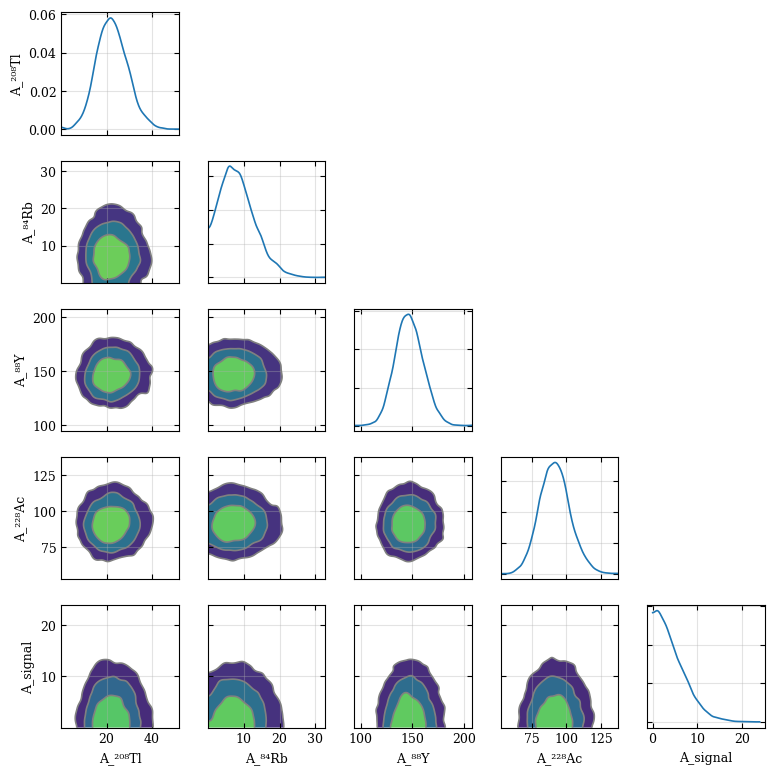

In [21]:
A_vars = [v for v in trace.posterior.data_vars if v.startswith("A_")]

axes = az.plot_pair(
    trace,
    var_names=A_vars,
    kind="kde",
    marginals=True,
    figsize=(8, 8),
    textsize=9,
)

for ax in axes.flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.show()

In [22]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
signal_samples = trace.posterior["A_signal"].values.flatten()

N_signal_90 = np.percentile(signal_samples, 90)
N_signal_95 = np.percentile(signal_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on signal counts : {N_signal_90:.3f}")
print(f"95% upper limit on signal counts : {N_signal_95:.3f}")
print("=" * 60)


90% upper limit on signal counts : 9.172
95% upper limit on signal counts : 11.008


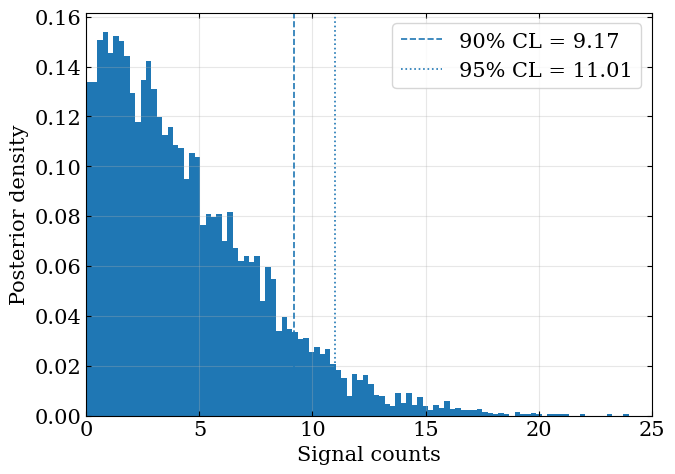

In [23]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(7, 5))

plt.hist(signal_samples, bins=100, density=True)

plt.axvline(
    N_signal_90,
    linestyle="--",
    label=f"90% CL = {N_signal_90:.2f}",
)

plt.axvline(
    N_signal_95,
    linestyle=":",
    label=f"95% CL = {N_signal_95:.2f}",
)

plt.xlabel("Signal counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.xlim(0,25)
plt.legend()

plt.tight_layout()
plt.show()



In [24]:
# posterior extraction
# ============================================================
# POSTERIOR EXTRACTION
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

idata = trace
posterior = idata.posterior

Q_s = posterior["Q"].values.reshape(-1)

A_signal_s = posterior["A_signal"].values.reshape(-1)
mu_signal_s = posterior["mu_signal"].values.reshape(-1)

A_bg_s = {
    name: posterior[f"A_{name}"].values.reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"].values.reshape(-1)
    for name in background_names
}

In [25]:
import numpy as np
import scipy.special


# ============================================================
# ESTRAZIONE POSTERIOR DEI PARAMETRI
# ============================================================

posterior = trace.posterior

n_samples = (
    posterior.sizes["chain"]
    *
    posterior.sizes["draw"]
)

print(f"Number of posterior samples: {n_samples}")


# ============================================================
# SIGNAL PARAMETERS
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .flatten()
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .flatten()
)


# ============================================================
# FLAT BACKGROUND
# ============================================================

Q_s = (
    posterior["Q"]
    .values
    .flatten()
)



# ============================================================
# BACKGROUND PEAK PARAMETERS
# ============================================================

A_bg_s = []
mu_bg_s = []


for name in BACKGROUND_PEAKS:

    A_bg_s.append(
        posterior[f"A_{name}"]
        .values
        .flatten()
    )

    mu_bg_s.append(
        posterior[f"mu_{name}"]
        .values
        .flatten()
    )


# trasformo in numpy array

A_bg_s = np.array(A_bg_s)

mu_bg_s = np.array(mu_bg_s)



print("A_bg shape:", A_bg_s.shape)
print("mu_bg shape:", mu_bg_s.shape)



# ============================================================
# STORAGE DELLE CURVE POSTERIOR
# ============================================================

lambda_total_samples = []

lambda_bkg_samples = []

n_samples = 100

# ============================================================
# LOOP SUI CAMPIONI POSTERIOR
# ============================================================

for i in range(n_samples):


    # --------------------------------------------------------
    # ENERGY DEPENDENT RESOLUTION
    # --------------------------------------------------------

    mu_sig = mu_signal_s[i]

    sigma_i = sigma_fun(mu_sig).eval()



    # --------------------------------------------------------
    # SIGNAL CONTRIBUTION
    # --------------------------------------------------------

    sig_integral = (
        0.5 *
        (
            1
            +
            scipy.special.erf(
                (edges_high - mu_sig)
                /
                (sigma_i*np.sqrt(2))
            )
        )
        -
        0.5 *
        (
            1
            +
            scipy.special.erf(
                (edges_low - mu_sig)
                /
                (sigma_i*np.sqrt(2))
            )
        )
    )


    signal_i = (
        A_signal_s[i]
        *
        sig_integral
    )



    # --------------------------------------------------------
    # BACKGROUND PEAKS
    # --------------------------------------------------------

    bg_i = np.zeros_like(edges_low)



    for j in range(len(BACKGROUND_PEAKS)):


        mu_bg_i = mu_bg_s[j,i]


        bg_integral = (
            0.5 *
            (
                1
                +
                scipy.special.erf(
                    (edges_high - mu_bg_i)
                    /
                    (sigma_i*np.sqrt(2))
                )
            )
            -
            0.5 *
            (
                1
                +
                scipy.special.erf(
                    (edges_low - mu_bg_i)
                    /
                    (sigma_i*np.sqrt(2))
                )
            )
        )


        bg_i += (
            A_bg_s[j,i]
            *
            bg_integral
        )



    # --------------------------------------------------------
    # FLAT BACKGROUND
    # --------------------------------------------------------
    
    flat_i = (
        Q_s[i]
        *
        bin_width
    )
    #flat_i = Q_s[i] * np.ones_like(edges_low)



    # --------------------------------------------------------
    # ONLY BACKGROUND
    # --------------------------------------------------------

    bkg_model_i = (
        flat_i
        +
        bg_i
    )



    # --------------------------------------------------------
    # TOTAL MODEL
    # --------------------------------------------------------

    total_model_i = (
        bkg_model_i
        +
        signal_i
    )



    lambda_bkg_samples.append(
        bkg_model_i
    )


    lambda_total_samples.append(
        total_model_i
    )



# ============================================================
# ARRAY FINALI
# ============================================================

lambda_bkg_samples = np.array(
    lambda_bkg_samples
)


lambda_total_samples = np.array(
    lambda_total_samples
)



print(
    "Total posterior curves:",
    lambda_total_samples.shape
)

print(
    "Background posterior curves:",
    lambda_bkg_samples.shape
)



# ============================================================
# STATISTICHE POSTERIOR
# ============================================================


# ---- TOTAL MODEL ----

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)


lambda_total_low = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)


lambda_total_high = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)



# ---- BACKGROUND ONLY ----

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)


lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)


lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)



print("Done.")

Number of posterior samples: 8000
A_bg shape: (4, 8000)
mu_bg shape: (4, 8000)
Total posterior curves: (100, 190)
Background posterior curves: (100, 190)
Done.


In [26]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

# totale
fit_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

fit_total_low_68 = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

fit_total_high_68 = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


fit_total_low_95 = np.percentile(
    lambda_total_samples,
    2.5,
    axis=0
)

fit_total_high_95 = np.percentile(
    lambda_total_samples,
    97.5,
    axis=0
)



# background
fit_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

fit_bkg_low_68 = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

fit_bkg_high_68 = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


fit_bkg_low_95 = np.percentile(
    lambda_bkg_samples,
    2.5,
    axis=0
)

fit_bkg_high_95 = np.percentile(
    lambda_bkg_samples,
    97.5,
    axis=0
)

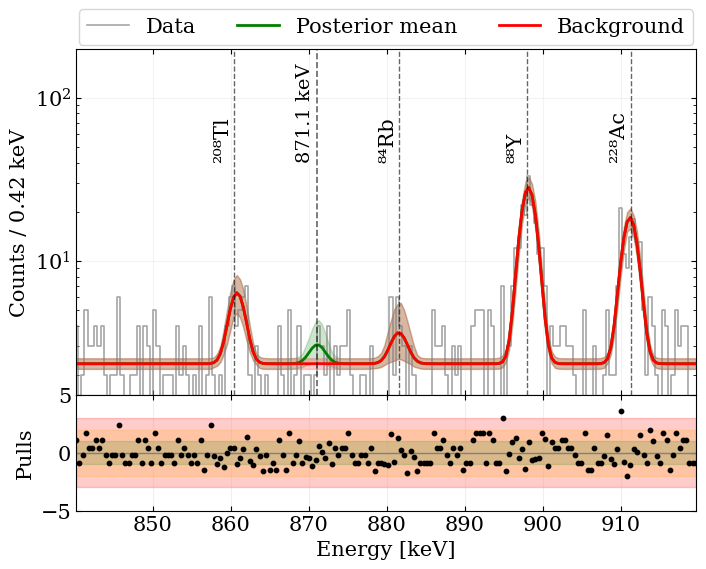

In [27]:
# ============================================================
# BAYESIAN FIT BAND
# ============================================================

# lambda_total_samples:
# (N_posterior_samples, N_bins)

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    5,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    95,
    axis=0
)


# background only

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    5,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    95,
    axis=0
)



# ============================================================
# RESIDUALS
# ============================================================

residuals = (
    counts_roi - lambda_total_mean
) / np.sqrt(lambda_total_mean + 1e-9)



# ============================================================
# BIN CENTERS
# ============================================================

E_roi = 0.5*(edges_low + edges_high)



# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    sharex=True,
    gridspec_kw={"height_ratios": [3,1]},
    figsize=(8,6)
)



# ============================================================
# DATA
# ============================================================

ax1.step(
    E_roi,
    counts_roi,
    where="mid",
    color="grey",
    alpha=0.7,
    label="Data"
)



# ============================================================
# TOTAL BAYESIAN MODEL
# ============================================================

ax1.plot(
    E_roi,
    lambda_total_mean,
    #where="mid",
    color="green",
    lw=2,
    label="Posterior mean"
)


ax1.fill_between(
    E_roi,
    lambda_total_low,
    lambda_total_high,
    #step="mid",
    color="green",
    alpha=0.2,
    #label="68% credible interval"
)



# ============================================================
# BACKGROUND ONLY
# ============================================================

ax1.plot(
    E_roi,
    lambda_bkg_mean,
    #where="mid",
    color="red",
    lw=2,
    label="Background"
)


ax1.fill_between(
    E_roi,
    lambda_bkg_low,
    lambda_bkg_high,
    #step="mid",
    color="red",
    alpha=0.2
)



# ============================================================
# BACKGROUND PEAK LINES
# ============================================================

for name, peak in BACKGROUND_PEAKS.items():

    ax1.axvline(
        peak["E"] ,
        color="black",
        linestyle="--",
        alpha=0.6,
        lw=1
    )

    ax1.text(
        peak["E"] - 1.5,
        40,
        name,
        rotation=90,
        verticalalignment="bottom",
        horizontalalignment="center",
        fontsize=15
    )



# ============================================================
# SIGNAL LINE
# ============================================================

ax1.axvline(
    SIGNAL["mu"],
    color="black",
    linestyle="--",
    alpha=0.6
)


ax1.text(
    SIGNAL["mu"]-1.5,
    40,
    "871.1 keV",
    rotation=90,
    verticalalignment="bottom",
    horizontalalignment="center",
    fontsize=14
)



# ============================================================
# AXES
# ============================================================

ax1.set_yscale("log")

ax1.set_xlim(
    E_roi.min(),
    E_roi.max()
)


ax1.set_ylim(
    1.5,
    200
    
)


ax1.set_ylabel(
    f"Counts / {edges_high[0]-edges_low[0]:.2f} keV"
)


ax1.grid(alpha=0.15)


ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5,0.98),
    ncol=3
)



# ============================================================
# RESIDUALS
# ============================================================

ax2.scatter(
    E_roi,
    residuals,
    s=10,
    color="black",
    zorder = 5
)


ax2.axhspan(
    -3,
    3,
    color="red",
    alpha=0.2
)


ax2.axhspan(
    -2,
    2,
    color="orange",
    alpha=0.2
)


ax2.axhspan(
    -1,
    1,
    color="green",
    alpha=0.15
)


ax2.axhline(
    0,
    color="gray",
    lw=1,
    zorder=2
)



ax2.set_xlabel(
    "Energy [keV]"
)


ax2.set_ylabel(
    "Pulls"
)


ax2.set_ylim(
    -5,
    5
)


ax2.grid(alpha=0.2)



plt.subplots_adjust(hspace=0)

plt.show()

In [28]:
import arviz as az

az.summary(
    trace,
    var_names=["Q","A_signal"]
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Q,5.550,0.303,4.99,6.111,0.003,0.003,7659.0,6004.0,1.0
A_signal,4.432,3.444,0.00,10.574,0.037,0.041,5313.0,2839.0,1.0


# half life

In [29]:

# Dati campione
m_sample = 551.3        # massa ZrO2 in grammi
Mr_sample = 123.22      # massa molare ZrO2 [g/mol]
N_A = 6.022e23          # numero di Avogadro
eff_94Zr = 0.0294935    # efficienza di rivelazione
i_a_94Zr = 0.1738       # abbondanza isotopica
t_live =    t_tot/(60*60*24*365)             # 90 giorni in anni

N_nuclei = (m_sample * i_a_94Zr / Mr_sample) * N_A


In [30]:
N_signal_90

np.float64(9.172097868852157)

In [31]:
# Numero di nuclei 96Zr nel campione
N_nuclei = (m_sample * i_a_94Zr / Mr_sample) * N_A

percentile = 90
T_half_limit = (np.log(2) * N_nuclei * eff_94Zr * t_live) /N_signal_90
print(f"T1/2 > {T_half_limit:.2e} yrs at {percentile}%")

T1/2 > 3.92e+20 yrs at 90%


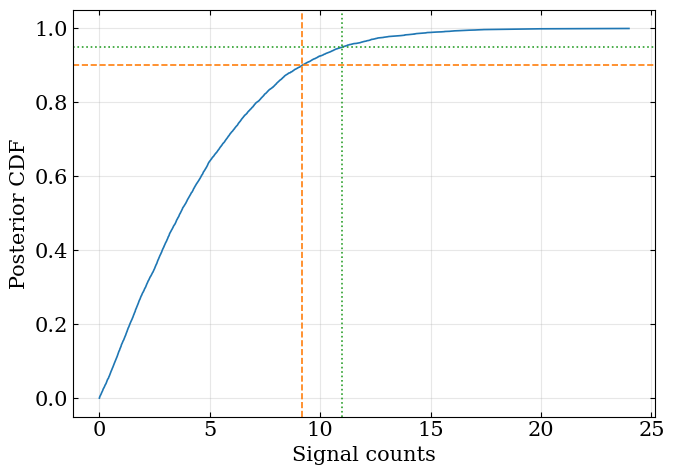

In [32]:
x = np.sort(signal_samples)
cdf = np.arange(1, len(x)+1)/len(x)

plt.figure(figsize=(7,5))

plt.plot(x, cdf)

plt.axhline(0.90, ls="--", color="C1")
plt.axhline(0.95, ls=":", color="C2")

plt.axvline(N_signal_90, ls="--", color="C1")
plt.axvline(N_signal_95, ls=":", color="C2")

plt.xlabel("Signal counts")
plt.ylabel("Posterior CDF")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

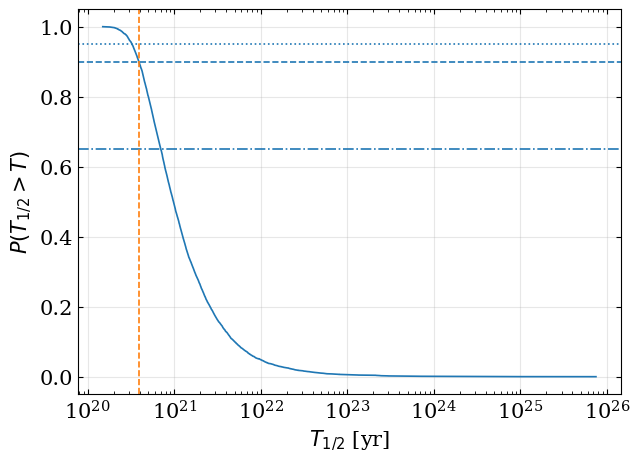

In [33]:
K = np.log(2) * N_nuclei * eff_94Zr * t_live

T_samples = K / signal_samples
T_samples = T_samples[np.isfinite(T_samples)]

T = np.sort(T_samples)

survival = 1 - np.arange(1, len(T)+1)/len(T)

plt.figure(figsize=(7,5))

plt.plot(T, survival)

plt.xscale("log")

plt.axhline(0.90, ls='--')
plt.axhline(0.95, ls=':')
plt.axhline(0.65, ls='-.')
plt.axvline(T_half_limit, ls='--', color="C1", label=f"90% CL = {T_half_limit:.2e} yrs")


plt.xlabel(r"$T_{1/2}$ [yr]")
plt.ylabel(r"$P(T_{1/2}>T)$")

plt.grid(alpha=0.3)

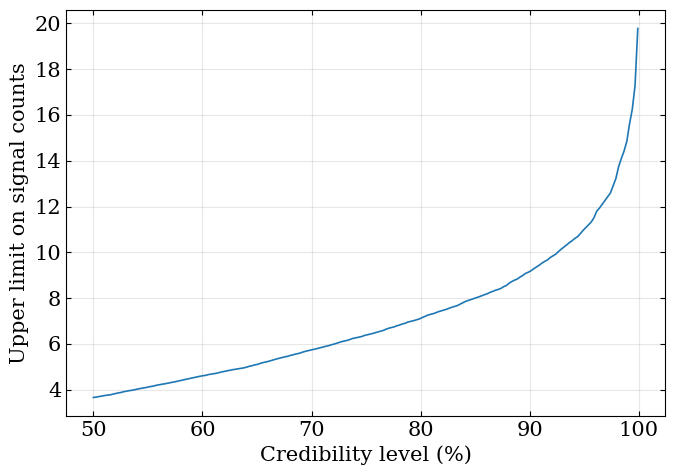

In [34]:
cls = np.linspace(50, 99.9, 200)
limits = np.percentile(signal_samples, cls)

plt.figure(figsize=(7,5))

plt.plot(cls, limits)

plt.xlabel("Credibility level (%)")
plt.ylabel("Upper limit on signal counts")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

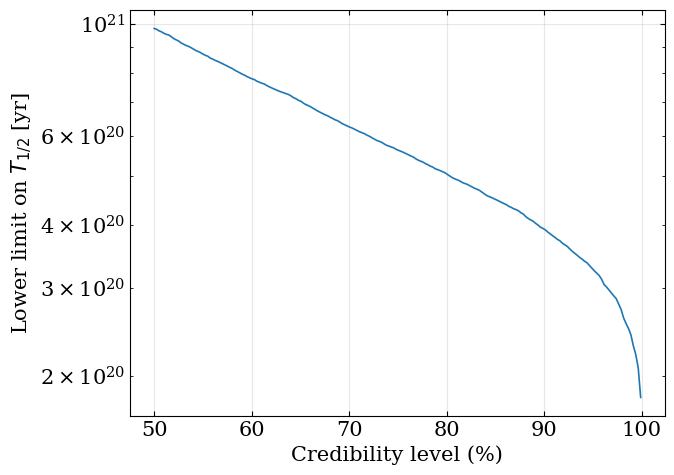

In [35]:
K = np.log(2) * N_nuclei * eff_94Zr * t_live

T_limits = K / limits

plt.figure(figsize=(7,5))

plt.plot(cls, T_limits)

plt.yscale("log")

plt.xlabel("Credibility level (%)")
plt.ylabel(r"Lower limit on $T_{1/2}$ [yr]")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

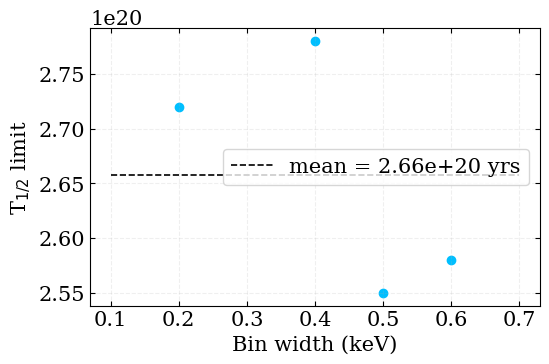

In [32]:
limit = [2.72e+20, 2.78e+20, 2.55e+20, 2.58e+20]

bd = [ 0.2, 0.4, 0.5, 0.6]



plt.scatter(bd, limit, color = 'deepskyblue')
plt.hlines(np.mean(limit), min(bd)-0.1, max(bd)+0.1, color = 'black', ls = '--', label = f"mean = {np.mean(limit):.2e} yrs")
plt.ylabel(fr"T$_{{1/2}}$ limit")
plt.xlabel('Bin width (keV)')
plt.legend(loc = 'center right')
plt.grid(alpha = 0.2, ls = '--')

# 84Rb activity

In [38]:


# ============================================================
# POSTERIOR OF 84Rb
# ============================================================
Rb84_samples = trace.posterior["A_84Rb + 206Pb(n,gamma)"].values.flatten()

N_84Rb_90 = np.percentile(Rb84_samples, 90)
N_84Rb_95 = np.percentile(Rb84_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on 84Rb counts : {N_84Rb_90:.3f}")
print(f"95% upper limit on 84Rb counts : {N_84Rb_95:.3f}")
print("=" * 60)


90% upper limit on 84Rb counts : 13.313
95% upper limit on 84Rb counts : 15.443


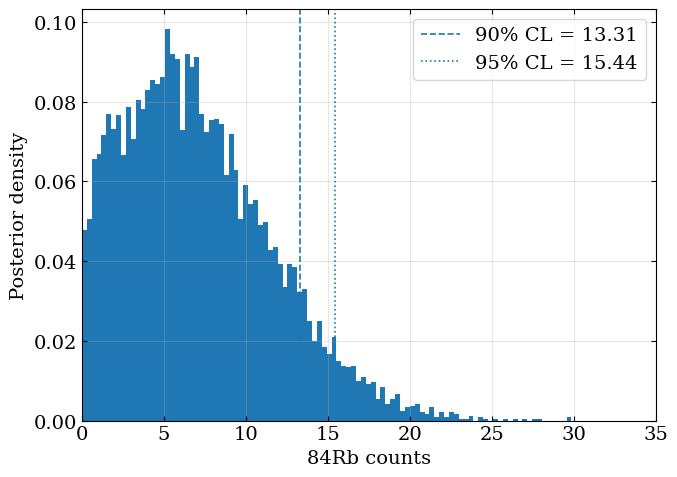

In [39]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(7, 5))

plt.hist(Rb84_samples, bins=100, density=True)

plt.axvline(
    N_84Rb_90,
    linestyle="--",
    label=f"90% CL = {N_84Rb_90:.2f}",
)

plt.axvline(
    N_84Rb_95,
    linestyle=":",
    label=f"95% CL = {N_84Rb_95:.2f}",
)

plt.xlabel("84Rb counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.xlim(0,35)
plt.legend()

plt.tight_layout()
plt.show()



In [40]:
np.median(Rb84_samples/(t_tot /(60*60*24)))

np.float64(0.04765813232225305)

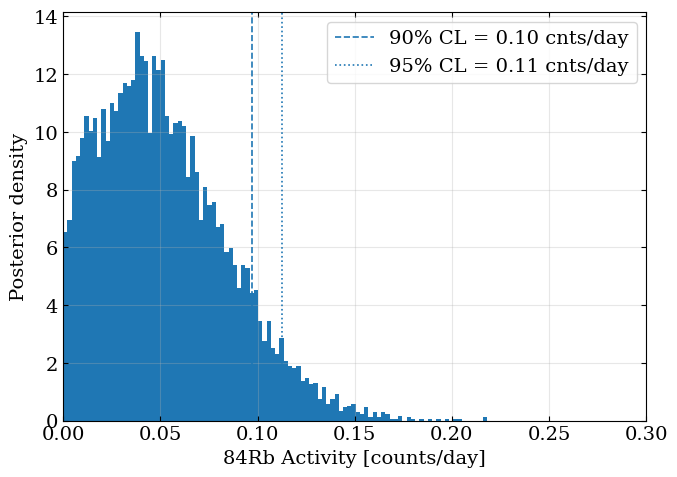

In [41]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(7, 5))

plt.hist(Rb84_samples / (t_tot /(60*60*24)), bins=100, density=True)

plt.axvline(
    np.percentile(Rb84_samples, 90) / (t_tot /(60*60*24)),
    linestyle="--",
    label=f"90% CL = {np.percentile(Rb84_samples, 90) / (t_tot /(60*60*24)):.2f} cnts/day",
)

plt.axvline(
    np.percentile(Rb84_samples, 95) / (t_tot /(60*60*24)),
    linestyle=":",
    label=f"95% CL = {np.percentile(Rb84_samples, 95) / (t_tot /(60*60*24)):.2f} cnts/day",
)

plt.xlabel("84Rb Activity [counts/day]")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.xlim(0,0.3)
plt.legend()

plt.tight_layout()
plt.show()



In [37]:
t_tot/(60*60*24)

136.9144560185185